In [1]:
import pandas as pd

df = pd.read_csv("Dataset1.csv")
df.head()


,SN,Train_No,Station_Code,1A,2A,3A,SL,Station_Name,Route_Number,Arrival_time,Departure_Time,Distance
0,1,107,SWV,100,100,100,100,SAWANTWADI R,1,00:00:00,10:25:00,0
1,2,107,THVM,260,228,196,164,THIVIM,1,11:06:00,11:08:00,32
2,3,107,KRMI,345,296,247,198,KARMALI,1,11:28:00,11:30:00,49
3,4,107,MAO,490,412,334,256,MADGOAN JN.,1,12:10:00,00:00:00,78
4,1,108,MAO,100,100,100,100,MADGOAN JN.,1,00:00:00,20:30:00,0


In [2]:
df["Arrival_time"] = pd.to_datetime(df["Arrival_time"], format="mixed", errors="coerce")
df["Departure_Time"] = pd.to_datetime(df["Departure_Time"], format="mixed", errors="coerce")


In [3]:
df["Journey_Duration"] = (
    df["Arrival_time"] - df["Departure_Time"]
).dt.total_seconds() / 60


In [4]:
df = df[df["Journey_Duration"] > 0]


In [5]:
from sklearn.model_selection import train_test_split

X = df[["Distance"]]
y = df["Journey_Duration"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [6]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)


LinearRegression()

In [7]:
y_pred = model.predict(X_test)


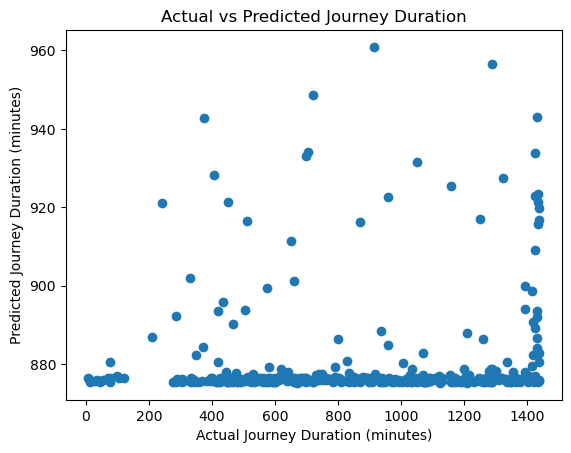

In [8]:
import matplotlib.pyplot as plt

plt.figure()
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Journey Duration (minutes)")
plt.ylabel("Predicted Journey Duration (minutes)")
plt.title("Actual vs Predicted Journey Duration")
plt.show()
